# 05. Діалоги: розмітка і перевірка моделей

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.append(str(Path("..").resolve()))
from fabula_annotation import write_annotation_workbook

SEED = 42
DIALOG_FILE = Path("../data/raw/dailydialog/data/dialogues.json")
ANNOTATION_DIR = Path("../annotation")
ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)
N_ITEMS = 300
N_REPEAT = 75
LENGTH_BINS = [(3, 5), (6, 9), (10, 14), (15, 30)]
WORD_PATTERN = re.compile(r"[A-Za-z0-9]+(?:'[A-Za-z]+)?")

## 1. Репліки DailyDialog (test)

In [2]:
dialogues = json.load(open(DIALOG_FILE, encoding="utf-8"))
rows = []
for dialogue in dialogues:
    if dialogue["data_split"] != "test":
        continue
    turns = dialogue["turns"]
    for index, turn in enumerate(turns):
        utterance = turn["utterance"].strip()
        rows.append({
            "dialogue_id": dialogue["dialogue_id"],
            "utt_idx": turn["utt_idx"],
            "topic": dialogue["domains"][0],
            "context": turns[index - 1]["utterance"].strip() if index > 0 else "— початок діалогу —",
            "utterance": utterance,
            "n_words": len(WORD_PATTERN.findall(utterance)),
        })

utterances = pd.DataFrame(rows)
print(f"Діалогів: {utterances['dialogue_id'].nunique()}, реплік: {len(utterances)}")
utterances["n_words"].describe().round(1).to_frame("слів у репліці")

Діалогів: 1000, реплік: 7740


,слів у репліці
count,7740.0
mean,11.4
std,9.1
min,1.0
25%,6.0
50%,9.0
75%,14.0
max,180.0


## 2. Відбір 300 реплік

In [3]:
def length_bin(n_words):
    for low, high in LENGTH_BINS:
        if low <= n_words <= high:
            return f"{low}-{high}"
    return None


candidates = utterances.assign(length_bin=utterances["n_words"].map(length_bin)).dropna(subset=["length_bin"])
candidates = candidates.drop_duplicates("utterance").sample(frac=1, random_state=SEED)
candidates = candidates.drop_duplicates("dialogue_id")
print(f"Кандидатів (3–30 слів, одна репліка на діалог): {len(candidates)}")

per_bin = N_ITEMS // len(LENGTH_BINS)
topic_share = candidates["topic"].value_counts(normalize=True)
selected = []
for low, high in LENGTH_BINS:
    pool = candidates[candidates["length_bin"] == f"{low}-{high}"]
    quotas = (topic_share * per_bin).round().clip(lower=1).astype(int).sort_values()
    picked = pd.concat([pool[pool["topic"] == topic].head(quota) for topic, quota in quotas.items()])
    if len(picked) < per_bin:
        picked = pd.concat([picked, pool.drop(picked.index).head(per_bin - len(picked))])
    selected.append(picked.head(per_bin))

items = pd.concat(selected).sample(frac=1, random_state=SEED).reset_index(drop=True)
items.insert(0, "item_id", [f"I{index:03d}" for index in range(1, len(items) + 1)])
pd.crosstab(items["topic"], items["length_bin"], margins=True)

Кандидатів (3–30 слів, одна репліка на діалог): 993


length_bin,10-14,15-30,3-5,6-9,All
topic,,,,,
Attitude & Emotion,4,4,4,4,16
Culture & Education,1,1,0,1,3
Finance,2,2,2,2,8
Health,2,2,2,2,8
Ordinary Life,21,21,21,21,84
Politics,1,1,1,1,4
Relationship,24,24,25,24,97
School Life,3,3,3,3,12
Tourism,6,6,6,6,24


## 3. Файли для розмітки

In [4]:
round1_path = ANNOTATION_DIR / "dialogues_round1.xlsx"
round2_path = ANNOTATION_DIR / "dialogues_round2.xlsx"
items_path = ANNOTATION_DIR / "items.csv"

repeat = (items.groupby("length_bin", group_keys=False)
          .apply(lambda part: part.sample(N_REPEAT // len(LENGTH_BINS) + 1, random_state=SEED))
          .head(N_REPEAT).sample(frac=1, random_state=SEED + 1))
items["in_round2"] = items["item_id"].isin(repeat["item_id"])

if round1_path.exists():
    print("Файли розмітки вже існують, не перезаписую:", round1_path)
else:
    items.to_csv(items_path, index=False, encoding="utf-8")
    write_annotation_workbook(items, round1_path)
    write_annotation_workbook(repeat, round2_path,
                              "Повторна розмітка: відкривати не раніше ніж через 7 днів після завершення першої.")
    print("Створено:", items_path, round1_path, round2_path)

print(f"Раунд 1: {len(items)} реплік; раунд 2: {int(items['in_round2'].sum())} реплік")
items.head(10)[["item_id", "topic", "length_bin", "context", "utterance"]]

Файли розмітки вже існують, не перезаписую: ..\annotation\dialogues_round1.xlsx
Раунд 1: 300 реплік; раунд 2: 75 реплік


,item_id,topic,length_bin,context,utterance
0,I001,Relationship,10-14,I read that story too. They seem to be able to...,They sure can. Maybe they can interact with me...
1,I002,Ordinary Life,15-30,It's still too much. Can't you make it any che...,"Sorry, but this is the best price. You can't g..."
2,I003,Finance,10-14,I took out a life insurance policy and made yo...,Can you tell me why you want to buy it?
3,I004,Attitude & Emotion,3-5,"But not as good as your mother's, right?","Actually, it's better ..."
4,I005,School Life,15-30,More or less. I go to three different building...,That's because you don't know the short cuts. ...
5,I006,Politics,15-30,It's so small. The fact that there is public i...,Have you ever listened to AM radio? It's quite...
6,I007,Ordinary Life,10-14,How is that?,You can use it however many times you need to.
7,I008,Ordinary Life,6-9,This one is 1500 yuan.,It looks pretty good. I think I'll take it.
8,I009,School Life,3-5,May I ask a question?,"Yes, what's it?"
9,I010,Work,10-14,May I see your ticket please?,Here you are. Do you need to see my passport?


## 4. Розмітка авторки

In [5]:
import joblib
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoTokenizer
from transformers.utils import logging as transformers_logging

from fabula_annotation import read_annotation_workbook
from fabula_eval import LEVELS, adjacent_accuracy, bootstrap_ci, class_f1, evaluate, macro_f1, plot_confusion
from fabula_features import FEATURE_NAMES, FeatureExtractor
from fabula_transformer import FeatureScaler, HybridClassifier, predict_logits

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../results/05")
FIGURES_DIR = Path("../../docs/figures")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LEVEL_TO_ID = {"A1": 0, "A2": 1, "B1": 2, "B2": 3, "C1": 4, "C2": 4}

items = pd.read_csv(items_path)
round1 = read_annotation_workbook(round1_path)
round2 = read_annotation_workbook(round2_path)
corrections = pd.read_csv(ANNOTATION_DIR / "corrections.csv")

gold = items.merge(round1.rename(columns={"level": "level_original"}), on="item_id")
gold["level_final"] = gold["item_id"].map(corrections.set_index("item_id")["corrected_level"]).fillna(gold["level_original"])
gold["level_id"] = gold["level_final"].map(LEVEL_TO_ID)
gold["level_class"] = gold["level_id"].map(dict(enumerate(LEVELS)))
gold.to_csv(RESULTS_DIR / "gold.csv", index=False, encoding="utf-8")
print(f"Реплік: {len(gold)}, виправлень: {(gold['level_original'] != gold['level_final']).sum()}, "
      f"не впевнена: {int(gold['unsure'].sum())}")
pd.crosstab(gold["length_bin"], gold["level_class"], margins=True).reindex(["3-5", "6-9", "10-14", "15-30", "All"])

Реплік: 300, виправлень: 5, не впевнена: 21


level_class,A1,A2,B1,B2,C,All
length_bin,,,,,,
3-5,36,26,9,3,1,75
6-9,13,30,18,9,5,75
10-14,3,14,31,22,5,75
15-30,0,9,25,30,11,75
All,52,79,83,64,22,300


## 5. Повторна розмітка (одразу після першої)

In [6]:
repeat = round1.merge(round2, on="item_id", suffixes=("_1", "_2"))
first, second = repeat["level_1"].map(LEVEL_TO_ID), repeat["level_2"].map(LEVEL_TO_ID)
difference = (first - second).abs()
pd.Series({
    "реплік": len(repeat),
    "точний збіг": round((difference == 0).mean(), 3),
    "збіг ±1": round((difference <= 1).mean(), 3),
    "каппа (квадратична)": round(cohen_kappa_score(first, second, weights="quadratic"), 3),
    "різниця 2+ рівні": int((difference >= 2).sum()),
}).to_frame("раунд 1 проти раунду 2")

,раунд 1 проти раунду 2
реплік,75.000
точний збіг,0.627
збіг ±1,0.960
каппа (квадратична),0.825
різниця 2+ рівні,3.000


## 6. Ознаки реплік

In [7]:
extractor = FeatureExtractor(Path("../data/raw/cefr-j"))
dialog_features = pd.DataFrame(extractor.extract_many(gold["utterance"].tolist()), columns=FEATURE_NAMES)
y_dialog = gold["level_id"].to_numpy()

train = pd.read_csv("../data/processed/features_train.csv")
cefr_test = pd.read_csv("../data/processed/features_test.csv")
comparison = pd.DataFrame({
    "CEFR-SP test": cefr_test[FEATURE_NAMES].mean(),
    "діалоги": dialog_features.mean(),
}).loc[["n_words", "share_oov", "min_zipf", "tree_depth", "n_contractions", "n_interjections",
        "is_question", "is_exclamation", "has_vocative", "is_fragment", "share_personal_pronouns"]]
comparison.round(3)

,CEFR-SP test,діалоги
n_words,13.308,11.373
share_oov,0.077,0.020
min_zipf,3.506,4.504
tree_depth,4.503,3.173
n_contractions,0.083,0.460
n_interjections,0.005,0.287
is_question,0.027,0.293
is_exclamation,0.005,0.030
has_vocative,0.003,0.040
is_fragment,0.020,0.070


## 7. Прогнози моделей

In [8]:
predictions = {}

m0 = joblib.load(MODELS_DIR / "m0_rules.joblib")
predictions["M0 rules"] = m0["model"].predict(dialog_features[m0["features"]])

m1 = make_pipeline(StandardScaler(), LogisticRegression(C=10.0, max_iter=3000, random_state=SEED))
m1.fit(train[FEATURE_NAMES], train["level_id"])
predictions["M1 Logistic Regression"] = m1.predict(dialog_features[FEATURE_NAMES])

m2 = joblib.load(MODELS_DIR / "m2_classic_best.joblib")
predictions["M2 Random Forest"] = m2["model"].predict(dialog_features[m2["features"]])

TRANSFORMERS = {
    "M3 DistilBERT": "m3_distilbert.pt",
    "M4-13": "m4_rf13.pt",
    "M4-33": "m4_all33.pt",
    "M4-final": "m4_hybrid.pt",
}
device = torch.device("cpu")
dialog_logits = {}
for name, file_name in TRANSFORMERS.items():
    checkpoint = torch.load(MODELS_DIR / file_name, map_location="cpu", weights_only=False)
    model = HybridClassifier(checkpoint["model_name"], n_features=len(checkpoint["features"]))
    model.load_state_dict({key: value.float() if value.is_floating_point() else value
                           for key, value in checkpoint["state_dict"].items()})
    tokenizer = AutoTokenizer.from_pretrained(checkpoint["model_name"])
    encoded = tokenizer(gold["utterance"].tolist(), padding="max_length", truncation=True,
                        max_length=checkpoint["max_length"], return_tensors="pt")
    features = None
    if checkpoint["features"]:
        scaler = FeatureScaler.from_dict(checkpoint["scaler"])
        features = torch.tensor(scaler.transform(dialog_features[checkpoint["features"]].to_numpy(dtype=np.float64)))
    logits = predict_logits(model, encoded["input_ids"], encoded["attention_mask"], features, device)
    dialog_logits[name] = logits
    predictions[name] = logits.argmax(axis=1)
    del model

prediction_table = gold[["item_id", "utterance", "length_bin", "level_class"]].copy()
for name, values in predictions.items():
    prediction_table[name] = [LEVELS[value] for value in values]
prediction_table.to_csv(RESULTS_DIR / "predictions.csv", index=False, encoding="utf-8")
prediction_table.head(8)

,item_id,utterance,length_bin,level_class,M0 rules,M1 Logistic Regression,M2 Random Forest,M3 DistilBERT,M4-13,M4-33,M4-final
0,I001,They sure can. Maybe they can interact with me...,10-14,B1,B2,B1,B1,B1,B1,B1,B1
1,I002,"Sorry, but this is the best price. You can't g...",15-30,A2,B2,B1,B1,B1,B1,B1,B1
2,I003,Can you tell me why you want to buy it?,10-14,A1,A2,A2,A2,A2,A2,A2,A2
3,I004,"Actually, it's better ...",3-5,A1,A2,A1,A2,A2,A2,A2,A2
4,I005,That's because you don't know the short cuts. ...,15-30,B1,B2,B1,B1,B1,B1,B1,B1
5,I006,Have you ever listened to AM radio? It's quite...,15-30,B1,B2,B1,B1,B1,B1,B1,B1
6,I007,You can use it however many times you need to.,10-14,B1,B1,A2,A2,A2,A2,B1,A2
7,I008,It looks pretty good. I think I'll take it.,6-9,A2,B1,A2,A2,A2,A2,A2,A2


## 8. CEFR-SP test проти діалогів

In [9]:
CEFR_TEST_RESULTS = {
    "M0 rules": ("../results/03_test.csv", "M0 rules"),
    "M1 Logistic Regression": ("../results/03_test.csv", "M1 Logistic Regression [max]"),
    "M2 Random Forest": ("../results/03_test.csv", "M2 Random Forest [max], 13 ознак"),
}
cefr_scores = {name: pd.read_csv(file, index_col=0).loc[row] for name, (file, row) in CEFR_TEST_RESULTS.items()}
for name, file_name in TRANSFORMERS.items():
    checkpoint_seed = torch.load(MODELS_DIR / file_name, map_location="cpu", weights_only=False)["seed"]
    run_name = {"M3 DistilBERT": "M3", "M4-13": "M4_rf13", "M4-33": "M4_all33", "M4-final": "M4_final"}[name]
    cefr_scores[name] = pd.Series(json.load(open(f"../results/04/{run_name}_seed{checkpoint_seed}.json"))["test"])

rows = {}
for name, values in predictions.items():
    dialog = evaluate(y_dialog, values)
    low, high = bootstrap_ci(y_dialog, values)
    rows[name] = {
        "CEFR-SP macro-F1": float(cefr_scores[name]["macro_f1"]),
        "діалоги macro-F1": dialog["macro_f1"],
        "діалоги 95% ДІ": f"[{low:.3f}; {high:.3f}]",
        "падіння": float(cefr_scores[name]["macro_f1"]) - dialog["macro_f1"],
        "CEFR-SP ±1": float(cefr_scores[name]["adjacent_accuracy"]),
        "діалоги ±1": dialog["adjacent_accuracy"],
        "CEFR-SP QWK": float(cefr_scores[name]["qwk"]),
        "діалоги QWK": dialog["qwk"],
        "діалоги F1 A1": dialog["f1_A1"],
        "діалоги F1 C": dialog["f1_C"],
    }
gap = pd.DataFrame(rows).T
gap.to_csv(RESULTS_DIR / "cefr_vs_dialogues.csv")
gap

,CEFR-SP macro-F1,діалоги macro-F1,діалоги 95% ДІ,падіння,CEFR-SP ±1,діалоги ±1,CEFR-SP QWK,діалоги QWK,діалоги F1 A1,діалоги F1 C
M0 rules,0.395163,0.42657,[0.368; 0.487],-0.031406,0.912059,0.88,0.590831,0.645996,0.585859,0.25641
M1 Logistic Regression,0.532134,0.268397,[0.222; 0.314],0.263737,0.98934,0.896667,0.764421,0.444062,0.246154,0.074074
M2 Random Forest,0.580042,0.32966,[0.274; 0.384],0.250381,0.983344,0.916667,0.769771,0.559122,0.262295,0.083333
M3 DistilBERT,0.616169,0.20597,[0.178; 0.233],0.410199,0.996669,0.89,0.814901,0.448022,0.0,0.0
M4-13,0.623631,0.197408,[0.173; 0.221],0.426223,0.996003,0.903333,0.818185,0.45845,0.0,0.0
M4-33,0.60899,0.22267,[0.189; 0.257],0.38632,0.996669,0.916667,0.812953,0.491943,0.109091,0.0
M4-final,0.620051,0.216641,[0.188; 0.244],0.40341,0.996003,0.913333,0.816038,0.491179,0.0,0.0


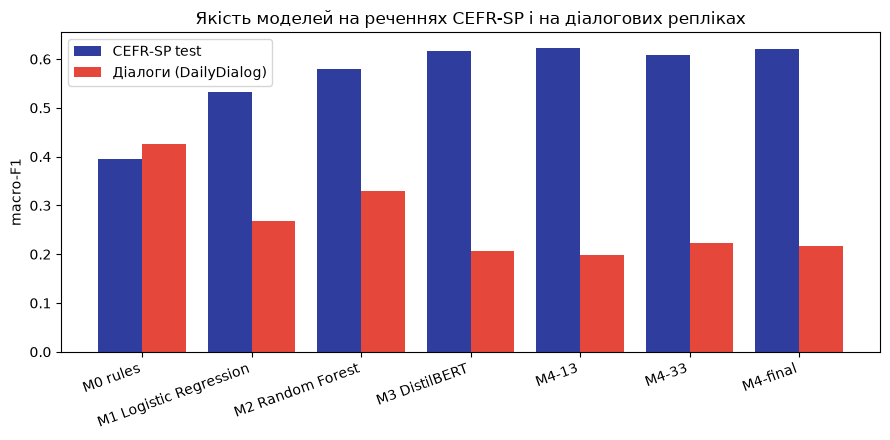

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(gap))
ax.bar(positions - 0.2, gap["CEFR-SP macro-F1"].astype(float), width=0.4, label="CEFR-SP test", color="#2F3E9E")
ax.bar(positions + 0.2, gap["діалоги macro-F1"].astype(float), width=0.4, label="Діалоги (DailyDialog)", color="#E5483B")
ax.set_xticks(positions, gap.index, rotation=20, ha="right")
ax.set_ylabel("macro-F1")
ax.set_title("Якість моделей на реченнях CEFR-SP і на діалогових репліках")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_cefr_vs_dialogues.png", dpi=150)
plt.show()

## 9. Якість за довжиною репліки

In [11]:
length_rows = {}
for length_bin in ["3-5", "6-9", "10-14", "15-30"]:
    mask = (gold["length_bin"] == length_bin).to_numpy()
    length_rows[length_bin] = {name: macro_f1(y_dialog[mask], values[mask]) for name, values in predictions.items()}
by_length = pd.DataFrame(length_rows)
by_length.to_csv(RESULTS_DIR / "macro_f1_by_length.csv")
by_length.round(3)

,3-5,6-9,10-14,15-30
M0 rules,0.245,0.262,0.250,0.221
M1 Logistic Regression,0.176,0.197,0.178,0.143
M2 Random Forest,0.180,0.233,0.226,0.205
M3 DistilBERT,0.098,0.214,0.224,0.169
M4-13,0.097,0.220,0.187,0.188
M4-33,0.176,0.234,0.172,0.196
M4-final,0.134,0.218,0.229,0.189


In [12]:
adjacent_rows = {}
for length_bin in ["3-5", "6-9", "10-14", "15-30"]:
    mask = (gold["length_bin"] == length_bin).to_numpy()
    adjacent_rows[length_bin] = {name: adjacent_accuracy(y_dialog[mask], values[mask]) for name, values in predictions.items()}
pd.DataFrame(adjacent_rows).round(3)

,3-5,6-9,10-14,15-30
M0 rules,0.880,0.880,0.920,0.840
M1 Logistic Regression,0.920,0.880,0.880,0.907
M2 Random Forest,0.960,0.880,0.880,0.947
M3 DistilBERT,0.960,0.853,0.853,0.893
M4-13,0.960,0.867,0.907,0.880
M4-33,0.973,0.907,0.907,0.880
M4-final,0.973,0.867,0.893,0.920


## 10. Зсув рівня: модель вище чи нижче за авторку

In [13]:
shift_rows = {}
for name, values in predictions.items():
    difference = values - y_dialog
    shift_rows[name] = {"середній зсув (рівнів)": difference.mean(), "вище": (difference > 0).mean(),
                        "точно": (difference == 0).mean(), "нижче": (difference < 0).mean()}
pd.DataFrame(shift_rows).T.round(3)

,середній зсув (рівнів),вище,точно,нижче
M0 rules,0.027,0.303,0.447,0.250
M1 Logistic Regression,-0.203,0.237,0.387,0.377
M2 Random Forest,-0.130,0.257,0.430,0.313
M3 DistilBERT,-0.313,0.213,0.380,0.407
M4-13,-0.247,0.240,0.373,0.387
M4-33,-0.220,0.240,0.390,0.370
M4-final,-0.267,0.217,0.397,0.387


In [14]:
distribution = pd.DataFrame({"авторка": pd.Series(y_dialog).value_counts()} | {
    name: pd.Series(values).value_counts() for name, values in predictions.items()
}).reindex(range(len(LEVELS))).fillna(0).astype(int).set_axis(LEVELS)
distribution

,авторка,M0 rules,M1 Logistic Regression,M2 Random Forest,M3 DistilBERT,M4-13,M4-33,M4-final
A1,52,47,13,9,0,1,3,0
A2,79,88,129,133,178,156,140,165
B1,83,67,144,123,114,135,153,126
B2,64,81,9,33,7,7,3,8
C,22,17,5,2,1,1,1,1


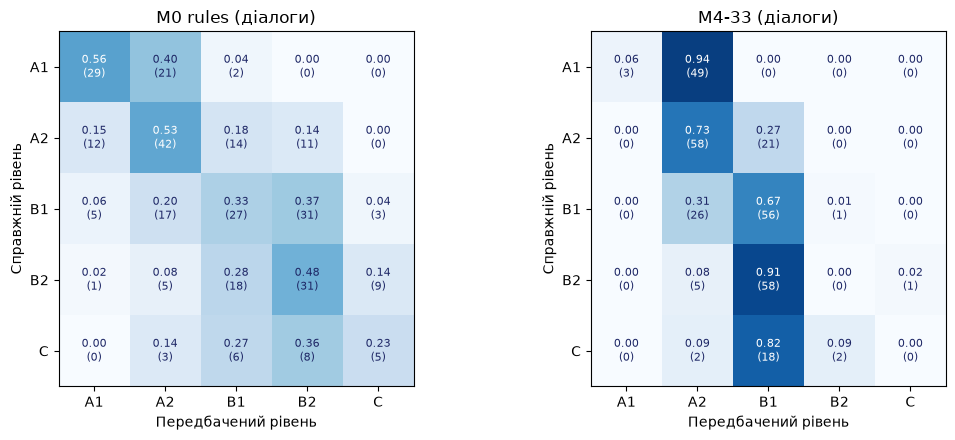

In [15]:
best_classic = max(["M0 rules", "M1 Logistic Regression", "M2 Random Forest"], key=lambda name: gap.loc[name, "діалоги macro-F1"])
best_transformer = max(TRANSFORMERS, key=lambda name: gap.loc[name, "діалоги macro-F1"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(y_dialog, predictions[best_classic], f"{best_classic} (діалоги)", ax=axes[0])
plot_confusion(y_dialog, predictions[best_transformer], f"{best_transformer} (діалоги)", ax=axes[1])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_confusion_dialogues.png", dpi=150)
plt.show()

## 11. Без реплік, у яких авторка не впевнена

In [16]:
confident = (~gold["unsure"].fillna(False).astype(bool)).to_numpy()
pd.DataFrame({name: evaluate(y_dialog[confident], values[confident]) for name, values in predictions.items()}).T[
    ["macro_f1", "accuracy", "adjacent_accuracy", "qwk"]].round(3)

,macro_f1,accuracy,adjacent_accuracy,qwk
M0 rules,0.445,0.459,0.892,0.663
M1 Logistic Regression,0.273,0.394,0.914,0.459
M2 Random Forest,0.337,0.437,0.939,0.599
M3 DistilBERT,0.199,0.376,0.907,0.466
M4-13,0.198,0.376,0.925,0.490
M4-33,0.224,0.394,0.932,0.509
M4-final,0.211,0.394,0.932,0.517


## 12. Діагностика: прогнози на CEFR-SP test збігаються з Colab

In [17]:
from scipy.stats import spearmanr

RUN_NAMES = {"M3 DistilBERT": "M3", "M4-13": "M4_rf13", "M4-33": "M4_all33", "M4-final": "M4_final"}
cefr_test_text = pd.read_csv("../data/processed/features_test.csv")
match_rows = {}
for name in ["M3 DistilBERT", "M4-33"]:
    checkpoint = torch.load(MODELS_DIR / TRANSFORMERS[name], map_location="cpu", weights_only=False)
    model = HybridClassifier(checkpoint["model_name"], n_features=len(checkpoint["features"]))
    model.load_state_dict({key: value.float() if value.is_floating_point() else value
                           for key, value in checkpoint["state_dict"].items()})
    tokenizer = AutoTokenizer.from_pretrained(checkpoint["model_name"])
    encoded = tokenizer(cefr_test_text["text"].tolist(), padding="max_length", truncation=True,
                        max_length=checkpoint["max_length"], return_tensors="pt")
    features = None
    if checkpoint["features"]:
        features = torch.tensor(FeatureScaler.from_dict(checkpoint["scaler"]).transform(
            cefr_test_text[checkpoint["features"]].to_numpy(dtype=np.float64)))
    local = predict_logits(model, encoded["input_ids"], encoded["attention_mask"], features, device).argmax(axis=1)
    colab = pd.read_csv(f"../results/04/{RUN_NAMES[name]}_seed{checkpoint['seed']}_test.csv")["prediction"].to_numpy()
    match_rows[name] = float(np.mean(local == colab))
    del model
pd.Series(match_rows).round(4).to_frame("збіг з Colab")

,збіг з Colab
M3 DistilBERT,0.9987
M4-33,1.0000


## 13. Діагностика: порядок (Спірмен) і на що спирається розмітка

In [18]:
def expected_level(logits):
    probabilities = np.exp(logits - logits.max(axis=1, keepdims=True))
    probabilities /= probabilities.sum(axis=1, keepdims=True)
    return probabilities @ np.arange(len(LEVELS))


def m0_score(features):
    length_level = np.searchsorted(m0["model"].length_thresholds_, features["n_words"].to_numpy(), side="right")
    return (length_level + np.clip(features["max_word_level"].to_numpy(), 0, len(LEVELS) - 1)) / 2


def colab_logits(name, split):
    seed = torch.load(MODELS_DIR / TRANSFORMERS[name], map_location="cpu", weights_only=False)["seed"]
    frame = pd.read_csv(f"../results/04/{RUN_NAMES[name]}_seed{seed}_{split}.csv")
    return frame[[f"logit_{level}" for level in LEVELS]].to_numpy()


cefr_validation = pd.read_csv("../data/processed/features_validation.csv")
y_cefr_test, y_cefr_validation = cefr_test_text["level_id"].to_numpy(), cefr_validation["level_id"].to_numpy()

dialog_scores = {"M0 rules": m0_score(dialog_features),
                 "M2 Random Forest": m2["model"].predict_proba(dialog_features[m2["features"]]) @ np.arange(len(LEVELS))}
cefr_scores_continuous = {"M0 rules": m0_score(cefr_test_text),
                          "M2 Random Forest": m2["model"].predict_proba(cefr_test_text[m2["features"]]) @ np.arange(len(LEVELS))}
for name in TRANSFORMERS:
    dialog_scores[name] = expected_level(dialog_logits[name])
    cefr_scores_continuous[name] = expected_level(colab_logits(name, "test"))

spearman_table = pd.DataFrame({
    "CEFR-SP test": {name: spearmanr(score, y_cefr_test).statistic for name, score in cefr_scores_continuous.items()},
    "діалоги": {name: spearmanr(score, y_dialog).statistic for name, score in dialog_scores.items()},
})
spearman_table.to_csv(RESULTS_DIR / "spearman.csv")
pd.DataFrame(dialog_scores).assign(item_id=gold["item_id"]).to_csv(RESULTS_DIR / "dialog_scores.csv", index=False)
spearman_table.round(3)

,CEFR-SP test,діалоги
M0 rules,0.603,0.670
M2 Random Forest,0.811,0.683
M3 DistilBERT,0.856,0.738
M4-13,0.859,0.746
M4-33,0.855,0.746
M4-final,0.859,0.754


In [19]:
simple = ["n_words", "max_word_level", "min_zipf", "share_oov", "tree_depth"]
pd.DataFrame({
    "фахівці CEFR-SP (test)": [spearmanr(cefr_test_text[c], y_cefr_test).statistic for c in simple],
    "авторка (діалоги)": [spearmanr(dialog_features[c], y_dialog).statistic for c in simple],
}, index=simple).round(3)

,фахівці CEFR-SP (test),авторка (діалоги)
n_words,0.525,0.629
max_word_level,0.510,0.525
min_zipf,-0.684,-0.517
share_oov,0.545,0.236
tree_depth,0.455,0.549


## 14. Поєднання M0 і трансформера (без даних діалогів)

In [20]:
WEIGHTS = np.round(np.arange(0, 1.01, 0.1), 1)


def to_level(score):
    return np.clip(np.floor(score + 0.5), 0, len(LEVELS) - 1).astype(int)


m0_validation, m0_test, m0_dialog = m0_score(cefr_validation), m0_score(cefr_test_text), m0_score(dialog_features)
ensemble_rows = {}
for name in ["M3 DistilBERT", "M4-33", "M4-final"]:
    validation_score = expected_level(colab_logits(name, "validation"))
    tuned = max(WEIGHTS, key=lambda w: macro_f1(y_cefr_validation, to_level(w * validation_score + (1 - w) * m0_validation)))
    for weight, label in [(tuned, f"w={tuned} (підібрано на CEFR-SP validation)"), (0.5, "w=0.5")]:
        cefr_prediction = to_level(weight * cefr_scores_continuous[name] + (1 - weight) * m0_test)
        dialog_prediction = to_level(weight * dialog_scores[name] + (1 - weight) * m0_dialog)
        ensemble_rows[f"{name} + M0, {label}"] = {
            "CEFR-SP macro-F1": macro_f1(y_cefr_test, cefr_prediction),
            "діалоги macro-F1": macro_f1(y_dialog, dialog_prediction),
            "діалоги QWK": evaluate(y_dialog, dialog_prediction)["qwk"],
            "діалоги ±1": adjacent_accuracy(y_dialog, dialog_prediction),
        }
ensemble = pd.DataFrame(ensemble_rows).T
ensemble.to_csv(RESULTS_DIR / "ensemble_m0.csv")
ensemble.round(3)

,CEFR-SP macro-F1,діалоги macro-F1,діалоги QWK,діалоги ±1
"M3 DistilBERT + M0, w=1.0 (підібрано на CEFR-SP validation)",0.535,0.200,0.443,0.890
"M3 DistilBERT + M0, w=0.5",0.503,0.396,0.615,0.903
"M4-33 + M0, w=1.0 (підібрано на CEFR-SP validation)",0.619,0.211,0.481,0.913
"M4-33 + M0, w=0.5",0.499,0.403,0.637,0.917
"M4-final + M0, w=1.0 (підібрано на CEFR-SP validation)",0.628,0.217,0.491,0.913
"M4-final + M0, w=0.5",0.487,0.406,0.630,0.910


## 15. Калібрування порогів на розмітці діалогів (5 × 5-fold)

In [21]:
from sklearn.model_selection import StratifiedKFold


def fit_thresholds(scores, labels):
    cumulative = [np.mean(labels <= level) for level in range(len(LEVELS) - 1)]
    return np.quantile(scores, cumulative)


def apply_thresholds(scores, thresholds):
    return np.searchsorted(thresholds, scores, side="right")


calibration_rows, oof_predictions = [], {}
for name, score in dialog_scores.items():
    for repeat in range(5):
        folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + repeat)
        prediction = np.zeros_like(y_dialog)
        for train_index, test_index in folds.split(score, y_dialog):
            thresholds = fit_thresholds(score[train_index], y_dialog[train_index])
            prediction[test_index] = apply_thresholds(score[test_index], thresholds)
        if repeat == 0:
            oof_predictions[name] = prediction
        calibration_rows.append({"name": name, "repeat": repeat, **evaluate(y_dialog, prediction)})

calibration = pd.DataFrame(calibration_rows)
calibration.to_csv(RESULTS_DIR / "calibration_cv.csv", index=False)
summary = calibration.groupby("name", sort=False)[["macro_f1", "accuracy", "adjacent_accuracy", "qwk", "f1_A1", "f1_C"]].agg(["mean", "std"])
summary.insert(0, ("без калібрування", "macro_f1"), [gap.loc[name, "діалоги macro-F1"] for name in summary.index])
summary.round(3)

без калібрування macro_f1        accuracy         \
                         macro_f1     mean    std     mean    std   
name                                                                
M0 rules                    0.427    0.396  0.004    0.396  0.004   
M2 Random Forest            0.330    0.491  0.008    0.493  0.008   
M3 DistilBERT               0.206    0.483  0.008    0.481  0.008   
M4-13                       0.197    0.503  0.006    0.501  0.009   
M4-33                       0.223    0.504  0.007    0.502  0.007   
M4-final                    0.217    0.501  0.006    0.501  0.007   

                 adjacent_accuracy           qwk         f1_A1          f1_C  \
                              mean    std   mean    std   mean    std   mean   
name                                                                           
M0 rules                     0.828  0.003  0.613  0.006  0.586  0.000  0.316   
M2 Random Forest             0.867  0.002  0.645  0.002  0.627  0.010  0.404   
M3 DistilBERT                0.917  0.004  0.711  0.006  0.703  0.005  0.398   
M4-13                        0.917  0.003  0.709  0.007  0.678  0.011  0.425   
M4-33                        0.910  0.005  0.706  0.007  0.648  0.024  0.451   
M4-final                     0.923  0.002  0.728  0.005  0.703  0.008  0.402   

                         
                    std  
name                     
M0 rules          0.000  
M2 Random Forest  0.010  
M3 DistilBERT     0.010  
M4-13             0.019  
M4-33             0.006  
M4-final          0.004

In [22]:
ci_rows = {}
for name, prediction in oof_predictions.items():
    low, high = bootstrap_ci(y_dialog, prediction)
    ci_rows[name] = {"macro-F1 (повтор 0)": macro_f1(y_dialog, prediction), "95% ДІ": f"[{low:.3f}; {high:.3f}]"}
pd.DataFrame(ci_rows).T

,macro-F1 (повтор 0),95% ДІ
M0 rules,0.402736,[0.348; 0.457]
M2 Random Forest,0.495227,[0.434; 0.554]
M3 DistilBERT,0.491461,[0.433; 0.547]
M4-13,0.49451,[0.435; 0.549]
M4-33,0.495738,[0.440; 0.552]
M4-final,0.500518,[0.441; 0.555]


## 16. Скільки розмічених реплік потрібно для калібрування

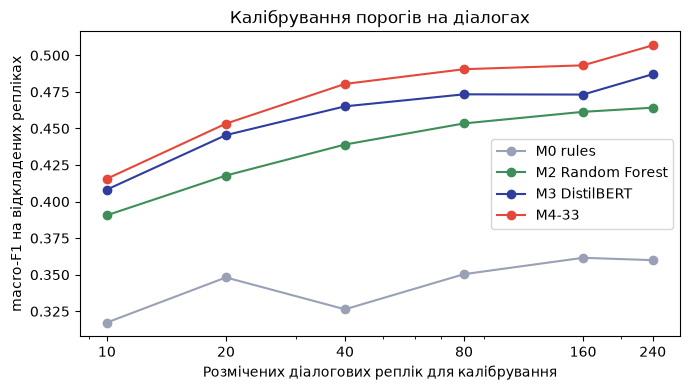

name,M0 rules,M2 Random Forest,M3 DistilBERT,M4-33
size,,,,
10,0.317,0.391,0.408,0.416
20,0.348,0.418,0.445,0.453
40,0.326,0.439,0.465,0.480
80,0.350,0.453,0.473,0.491
160,0.362,0.461,0.473,0.493
240,0.360,0.464,0.487,0.507


In [23]:
SIZES = [10, 20, 40, 80, 160, 240]
curve_rows = []
rng = np.random.default_rng(SEED)
for repeat in range(30):
    order = rng.permutation(len(y_dialog))
    held_out, pool = order[:60], order[60:]
    for size in SIZES:
        calibration_index = pool[:size]
        for name in ["M0 rules", "M2 Random Forest", "M3 DistilBERT", "M4-33"]:
            score = dialog_scores[name]
            thresholds = fit_thresholds(score[calibration_index], y_dialog[calibration_index])
            curve_rows.append({"name": name, "size": size,
                               "macro_f1": macro_f1(y_dialog[held_out], apply_thresholds(score[held_out], thresholds))})

curve = pd.DataFrame(curve_rows).groupby(["name", "size"])["macro_f1"].mean().unstack(0)
curve.to_csv(RESULTS_DIR / "calibration_curve.csv")

fig, ax = plt.subplots(figsize=(7, 4))
colors = {"M0 rules": "#9AA0B5", "M2 Random Forest": "#3E8E5A", "M3 DistilBERT": "#2F3E9E", "M4-33": "#E5483B"}
for name in curve.columns:
    ax.plot(curve.index, curve[name], marker="o", label=name, color=colors[name])
ax.set_xscale("log")
ax.set_xticks(SIZES, SIZES)
ax.set_xlabel("Розмічених діалогових реплік для калібрування")
ax.set_ylabel("macro-F1 на відкладених репліках")
ax.set_title("Калібрування порогів на діалогах")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_calibration_curve.png", dpi=150)
plt.show()
curve.round(3)

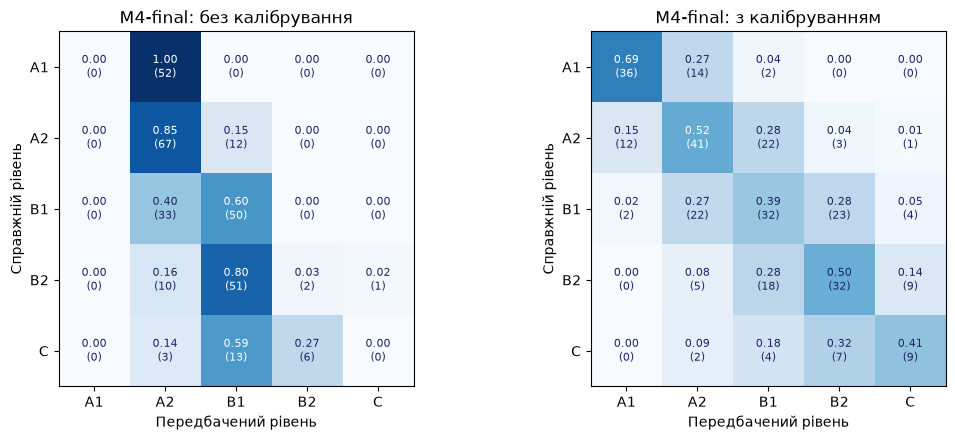

In [24]:
best_calibrated = "M4-final"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(y_dialog, predictions[best_calibrated], f"{best_calibrated}: без калібрування", ax=axes[0])
plot_confusion(y_dialog, oof_predictions[best_calibrated], f"{best_calibrated}: з калібруванням", ax=axes[1])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_confusion_calibrated.png", dpi=150)
plt.show()

## 17. Фінальна модель для ML-сервісу

In [25]:
FINAL_MODEL = "M4-final"
final_thresholds = fit_thresholds(dialog_scores[FINAL_MODEL], y_dialog)
final = {"model": FINAL_MODEL, "file": TRANSFORMERS[FINAL_MODEL], "score": "expected level (softmax @ [0..4])",
         "thresholds": [round(float(value), 4) for value in final_thresholds], "levels": LEVELS,
         "calibrated_on": "300 dialogue utterances annotated by the author"}
json.dump(final, open(RESULTS_DIR / "final_model.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
final

{'model': 'M4-final',
 'file': 'm4_hybrid.pt',
 'score': 'expected level (softmax @ [0..4])',
 'thresholds': [0.911, 1.2478, 1.9034, 2.2616],
 'levels': ['A1', 'A2', 'B1', 'B2', 'C'],
 'calibrated_on': '300 dialogue utterances annotated by the author'}

## 18. Висновки

| Модель | CEFR-SP macro-F1 | Діалоги, без калібрування | Діалоги, з калібруванням (5×5-fold) | QWK з калібруванням | ±1 з калібруванням | Спірмен на діалогах |
| --- | --- | --- | --- | --- | --- | --- |
| M0 rules | 0.395 | 0.427 | 0.396 | 0.613 | 0.828 | 0.670 |
| M2 Random Forest | 0.580 | 0.330 | 0.491 | 0.645 | 0.867 | 0.683 |
| M3 DistilBERT | 0.616 | 0.206 | 0.483 | 0.711 | 0.917 | 0.738 |
| M4-13 | 0.624 | 0.197 | 0.503 | 0.709 | 0.917 | 0.746 |
| M4-33 | 0.609 | 0.223 | **0.504** | 0.706 | 0.910 | 0.746 |
| M4-final | 0.620 | 0.217 | 0.501 | **0.728** | **0.923** | **0.754** |

- Розмітка: 300 реплік (A1 52, A2 79, B1 83, B2 64, C 22); 5 оцінок виправлено; повтор одразу після розмітки — точний збіг 0.627, ±1 0.960, QWK 0.825.
- Код перевірено: локальні прогнози трансформерів на CEFR-SP test збігаються з Colab на 99.9–100%; артефакти тексту в 8 з 300 реплік.
- Без калібрування навчені моделі на діалогах різко падають (DistilBERT 0.616 → 0.206), а M0 — ні (0.427). Причина не в порядку: за кореляцією Спірмена трансформери й на діалогах найкращі (0.74–0.75 проти 0.67 у M0).
- Ламається шкала: трансформери стискають прогнози до A2/B1 (зсув −0.22…−0.31 рівня). Розмітка авторки сильніше спирається на довжину (0.63 проти 0.53 у фахівців CEFR-SP) і слабше на рідкісні слова (0.24 проти 0.55); у діалогах слів поза словником 2.0% проти 7.7%.
- Калібрування порогів на розмічених діалогах повертає якість: трансформери 0.21 → 0.50 macro-F1, QWK 0.71–0.73, F1 A1 0.65–0.70. Достатньо 20–40 розмічених реплік, щоб трансформер обігнав M0.
- Поєднання з M0 без даних діалогів (w = 0.5) дає 0.40 на діалогах, але псує CEFR-SP (0.62 → 0.50); вага, підібрана на CEFR-SP, обирає лише трансформер. Як загальний спосіб не підходить.
- Гібрид після калібрування трохи кращий за M3 (0.50 проти 0.48; ДІ перетинаються).
- Фінальна модель для ML-сервісу: M4-final з порогами, відкаліброваними на всіх 300 репліках (`results/05/final_model.json`).